# Solutions · 14 · Residence-time distributions

Worked solutions to the exercises of [notebook 14](../notebooks/14_residence_time_distributions.ipynb). Try each exercise
yourself before reading its solution - the learning happens in the attempt. Solutions are one way to
answer each question; other correct approaches exist.

In [1]:
try:                      # on Google Colab (or anywhere engreact is missing): install it from GitHub
    import engreact
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engreact"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engreact import datasets, rtd
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

In [2]:
d = pd.read_csv(datasets.path("rtd_tracer_pulse.csv"), comment="#")
t, C = d.t_s.to_numpy(), d.C_g_m3.to_numpy()
base = np.polyfit(t[t > 140], C[t > 140], 1)
E = rtd.E_from_pulse(t, np.maximum(C - np.polyval(base, t), 0.0))

## Exercise 1

A step experiment gives F(t). Simulate one from the corrected E(t) of the notebook (cumulative integral), add 2 % noise, and recover E(t) by differentiation. Why is the pulse experiment preferred for the variance and the step for the mean?

pulse: mean 39.6 s, variance 409 s2
noisy step, differentiated: mean 52.3 s, variance 1484 s2 (both wrecked by the noise)
noisy step, mean from the integral of (1 - F): 40.2 s (robust)


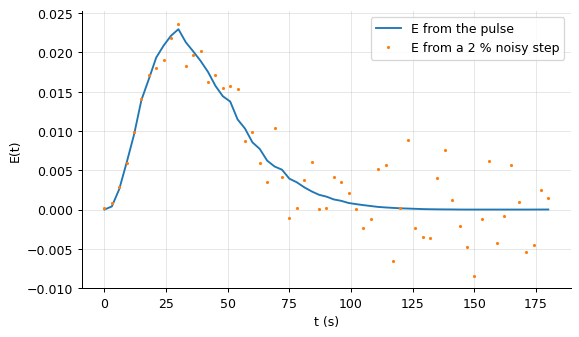

In [3]:
rng = np.random.default_rng(0)
F = rtd.F_from_E(t, E)
F_noisy = F * (1 + rng.normal(0, 0.02, F.size))
E_back = rtd.E_from_F(t, F_noisy)
trap = np.trapezoid if hasattr(np, "trapezoid") else np.trapz
mean_from_F = trap(1 - np.clip(F_noisy, 0, 1), t)                     # mean residence time = integral of (1 - F): no differentiation needed
m_step, m_pulse = rtd.moments(t, np.maximum(E_back, 0)), rtd.moments(t, E)
print(f"pulse: mean {m_pulse['mean']:.1f} s, variance {m_pulse['variance']:.0f} s2")
print(f"noisy step, differentiated: mean {m_step['mean']:.1f} s, variance {m_step['variance']:.0f} s2 (both wrecked by the noise)")
print(f"noisy step, mean from the integral of (1 - F): {mean_from_F:.1f} s (robust)")
plt.plot(t, E, label="E from the pulse"); plt.plot(t, E_back, ".", ms=3, label="E from a 2 % noisy step"); plt.xlabel("t (s)"); plt.ylabel("E(t)"); plt.legend(); plt.show()

Differentiating a noisy step amplifies the noise into a ragged E(t) whose moments are unreliable; but the
mean residence time can be taken from the step without differentiating, as the area above the F curve, and
that estimate is robust. The pulse is the better experiment for the variance, the step for the mean. In
practice both are run, and they must agree.

## Exercise 2

The vessel's design volume is 4.0 m3 and the flow 0.1 m3/s. Compare with the measured mean residence time. Is there dead volume, and how much? What would adsorption of the tracer on the walls do to the estimate?

In [4]:
V_design, v0 = 4.0, 0.1
tau_nominal = V_design / v0
m = rtd.moments(t, E)
print(f"nominal V/v0 = {tau_nominal:.1f} s; measured mean residence time {m['mean']:.1f} s -> effective volume {m['mean'] * v0:.2f} m3, dead volume {(1 - m['mean']/tau_nominal):.1%}")
print("adsorbing tracer: it lingers on the walls and leaves late, lengthening the mean - which would mask dead volume or invent 'extra' volume; the tracer must be inert")

nominal V/v0 = 40.0 s; measured mean residence time 39.6 s -> effective volume 3.96 m3, dead volume 1.0%
adsorbing tracer: it lingers on the walls and leaves late, lengthening the mean - which would mask dead volume or invent 'extra' volume; the tracer must be inert


A measured mean below $V/v_0$ means part of the vessel is stagnant; here the shortfall is small, within the
uncertainty of the flow measurement. An adsorbing tracer would bias the mean upward and could cancel a real
dead volume - a reason tracer tests use salts or dyes chosen for inertness.

## Exercise 3

**Implement it yourself:** write `moments(t, E)` returning mean, variance and skewness with trapezoidal integration and check it on the CSTR E(t) (skewness 2).

In [5]:
def moments(t, E):
    trap = np.trapezoid if hasattr(np, "trapezoid") else np.trapz
    area = trap(E, t); mean = trap(t * E, t) / area
    var = trap((t - mean) ** 2 * E, t) / area
    skew = trap((t - mean) ** 3 * E, t) / area / var ** 1.5
    return mean, var, skew
tt = np.linspace(0, 600, 60001)
print("CSTR E(t), tau = 10: (mean, variance, skewness) =", np.round(moments(tt, rtd.cstr_E(tt, 10.0)), 3), "- exact (10, 100, 2)")

CSTR E(t), tau = 10: (mean, variance, skewness) = [ 10. 100.   2.] - exact (10, 100, 2)


The exponential distribution has mean $\tau$, variance $\tau^2$ and skewness 2; the trapezoidal moments
reproduce them once the integration window covers the tail.